In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
#Loading CSV 
import pandas as pd

df = pd.read_csv(
    "DataCoSupplyChainDataset.csv",
    encoding="latin1"
)

print(df.shape)
print(df.head())

(172765, 52)
       Type  Days for shipping (real)  Days for shipment (scheduled)  \
0     DEBIT                         3                              4   
1  TRANSFER                         5                              4   
2      CASH                         4                              4   
3     DEBIT                         3                              4   
4   PAYMENT                         2                              4   

   Benefit per order  Sales per customer   Delivery Status  \
0          91.250000          314.640015  Advance shipping   
1        -249.089996          311.359985     Late delivery   
2        -247.779999          309.720001  Shipping on time   
3          22.860001          304.809998  Advance shipping   
4         134.210007          298.250000  Advance shipping   

   Late_delivery_risk  Category Id   Category Name Customer City  ...  \
0                   0           73  Sporting Goods        Caguas  ...   
1                   1           73 

In [4]:
#Data Overview
print('rows, colums',df.shape)
print('\ncolumns:')
print(df.columns.tolist())
print('\nNum Duplicates:',df.duplicated().sum)
print('\nMissing values (top20):')
print(df.isna().sum().sort_values(ascending=False).head(20))


rows, colums (172765, 52)

columns:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Fname', 'Customer Id', 'Customer Segment', 'Customer State', 'Customer Street', 'Department Id', 'Department Name', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Product Card Id', 'Product Category Id', 'Product Name', 'Product Price', 'Product Status', 'shipping date (DateOrders)', 'Shipping Mode', 'order Processing Time', 'Order Processing Time', 'Delay', 'Is_Delayed', 'order_month', 'order_day',

In [5]:
(df['Benefit per order']==df['Order Profit Per Order']).value_counts()


True    172765
Name: count, dtype: int64

In [6]:
columns_to_drop=[
    'Product Image',
    'Product Description',
    'Customer Email',
    'Customer Password',
    'Longitude',
    'Latitude',
    'Order Zipcode',
    'Customer Zipcode',
    'Customer Lname'
]

In [7]:
#Droping the Columsn that we don't need
df=df.drop(columns=columns_to_drop,errors="ignore")

In [8]:
#Removing Cancelled orders since they are not relevent dor delivery time analysis and may have different patterns than completed orders

df=df[df['Delivery Status']!='Shipping canceled']
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 172765 entries, 0 to 172764
Data columns (total 52 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           172765 non-null  object 
 1   Days for shipping (real)       172765 non-null  int64  
 2   Days for shipment (scheduled)  172765 non-null  int64  
 3   Benefit per order              172765 non-null  float64
 4   Sales per customer             172765 non-null  float64
 5   Delivery Status                172765 non-null  object 
 6   Late_delivery_risk             172765 non-null  int64  
 7   Category Id                    172765 non-null  int64  
 8   Category Name                  172765 non-null  object 
 9   Customer City                  172765 non-null  object 
 10  Customer Country               172765 non-null  object 
 11  Customer Fname                 172765 non-null  object 
 12  Customer Id                   

In [9]:
#Date Conversion
for c in ['order date (DateOrders)','shipping date (DateOrders)']:
    df[c]=pd.to_datetime(df[c],errors='coerce', dayfirst=False)

In [10]:
#Checking the Dataset After the Cleaning
print('rows,cols:',df.shape)
print('\nMissing values (top5):')
print(df.isna().sum().sort_values(ascending=False))

rows,cols: (172765, 52)

Missing values (top5):
Type                             0
Days for shipping (real)         0
Order Item Product Price         0
Order Item Profit Ratio          0
Order Item Quantity              0
Sales                            0
Order Item Total                 0
Order Profit Per Order           0
Order Region                     0
Order State                      0
Order Status                     0
Product Card Id                  0
Product Category Id              0
Product Name                     0
Product Price                    0
Product Status                   0
shipping date (DateOrders)       0
Shipping Mode                    0
order Processing Time            0
Order Processing Time            0
Delay                            0
Is_Delayed                       0
order_month                      0
order_day                        0
order_hour                       0
Order Item Id                    0
Order Item Discount Rate         0
Order I

In [11]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,shipping date (DateOrders),Shipping Mode,order Processing Time,Order Processing Time,Delay,Is_Delayed,order_month,order_day,order_hour,Profitablity Flag
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,2018-02-03 22:56:00,Standard Class,3,3,-1,False,1,Wednesday,22,Profit
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,2018-01-18 12:27:00,Standard Class,5,5,1,True,1,Saturday,12,Loss
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,2018-01-17 12:06:00,Standard Class,4,4,0,False,1,Saturday,12,Loss
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,2018-01-16 11:45:00,Standard Class,3,3,-1,False,1,Saturday,11,Profit
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,2018-01-15 11:24:00,Standard Class,2,2,-2,False,1,Saturday,11,Profit


In [12]:
#Creating Order Processing Time and delay
df['Order Processing Time']=(df['shipping date (DateOrders)']-df['order date (DateOrders)']).dt.days
df['Delay']=df['Order Processing Time']-df['Days for shipment (scheduled)']
df['Is_Delayed']=df['Delay'] > 0
df['order_month']=df['order date (DateOrders)'].dt.month
df['order_day']=df['order date (DateOrders)'].dt.day_name()
df['order_hour']=df['order date (DateOrders)'].dt.hour
df.describe()

,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Customer Id,Department Id,Order Customer Id,order date (DateOrders),...,Product Card Id,Product Category Id,Product Price,Product Status,shipping date (DateOrders),order Processing Time,Order Processing Time,Delay,order_month,order_hour
count,172765.000000,172765.000000,172765.000000,172765.000000,172765.000000,172765.000000,172765.000000,172765.000000,172765.000000,172765,...,172765.000000,172765.000000,172765.000000,172765.0,172765,172765.000000,172765.000000,172765.000000,172765.000000,172765.000000
mean,3.498596,2.933100,22.032360,183.165948,0.572900,31.856065,6687.759048,5.444095,6687.759048,2016-06-12 15:25:39.457991936,...,692.618858,31.856065,141.278595,0.0,2016-06-16 03:25:14.452927488,3.472816,3.472816,0.539716,6.235511,11.482604
min,0.000000,0.000000,-4274.979980,7.490000,0.000000,2.000000,1.000000,2.000000,1.000000,2015-01-01 00:00:00,...,19.000000,2.000000,9.990000,0.0,2015-01-03 00:00:00,0.000000,0.000000,-2.000000,1.000000,0.000000
25%,2.000000,2.000000,7.030000,104.379997,0.000000,18.000000,3252.000000,4.000000,3252.000000,2015-09-21 18:01:00,...,403.000000,18.000000,50.000000,0.0,2015-09-25 08:59:00,2.000000,2.000000,0.000000,3.000000,5.000000
50%,3.000000,4.000000,31.520000,163.990005,1.000000,29.000000,6457.000000,5.000000,6457.000000,2016-06-11 08:11:00,...,627.000000,29.000000,59.990002,0.0,2016-06-15 03:38:00,3.000000,3.000000,1.000000,6.000000,11.000000
75%,5.000000,4.000000,64.800003,247.399994,1.000000,45.000000,9782.000000,7.000000,9782.000000,2017-02-28 21:08:00,...,1004.000000,45.000000,199.990005,0.0,2017-03-04 08:00:00,5.000000,5.000000,1.000000,9.000000,17.000000
max,6.000000,4.000000,911.799988,1939.989990,1.000000,76.000000,20757.000000,12.000000,20757.000000,2018-01-31 23:38:00,...,1363.000000,76.000000,1999.989990,0.0,2018-02-06 22:14:00,6.000000,6.000000,4.000000,12.000000,23.000000
std,1.623446,1.373405,104.355313,120.141871,0.494659,15.642216,4165.069180,1.629248,4165.069180,NaN,...,336.471170,15.642216,139.862956,0.0,NaN,1.670187,1.670187,1.494150,3.405593,6.927276


In [13]:
df['Is_Delayed'].value_counts()

Is_Delayed
True     94523
False    78242
Name: count, dtype: int64

In [14]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Fname', 'Customer Id', 'Customer Segment',
       'Customer State', 'Customer Street', 'Department Id', 'Department Name',
       'Market', 'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Product Card Id', 'Product Category Id', 'Product Name',
       'Product Price', 'Product Status', 'shipping date (DateOrders)',
       'Shipping Mode', 'order Processing Time', 'Order Process

In [15]:
df['Order Profit Per Order']>0

0          True
1         False
2         False
3          True
4          True
          ...  
172760     True
172761    False
172762     True
172763     True
172764     True
Name: Order Profit Per Order, Length: 172765, dtype: bool

In [16]:
#Profitability Flag based on order profit per order
df['Profitablity Flag']=np.where(df['Order Profit Per Order'] > 0, 'Profit' ,np.where(df['Order Profit Per Order'] < 0, 'Loss', 'Break-even'))
df['Profitablity Flag'].value_counts()

Profitablity Flag
Profit        139354
Loss           32295
Break-even      1116
Name: count, dtype: int64

In [17]:
profitablilty_summary=(df['Profitablity Flag'].value_counts(normalize=True) * 100)
print(profitablilty_summary)

Profitablity Flag
Profit        80.661014
Loss          18.693022
Break-even     0.645964
Name: proportion, dtype: float64


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 172765 entries, 0 to 172764
Data columns (total 52 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   Type                           172765 non-null  object        
 1   Days for shipping (real)       172765 non-null  int64         
 2   Days for shipment (scheduled)  172765 non-null  int64         
 3   Benefit per order              172765 non-null  float64       
 4   Sales per customer             172765 non-null  float64       
 5   Delivery Status                172765 non-null  object        
 6   Late_delivery_risk             172765 non-null  int64         
 7   Category Id                    172765 non-null  int64         
 8   Category Name                  172765 non-null  object        
 9   Customer City                  172765 non-null  object        
 10  Customer Country               172765 non-null  object        
 11  

In [19]:
summary_statistics = df.describe().T

summary_statistics

,count,mean,min,25%,50%,75%,max,std
Days for shipping (real),172765.0,3.498596,0.0,2.0,3.0,5.0,6.0,1.623446
Days for shipment (scheduled),172765.0,2.9331,0.0,2.0,4.0,4.0,4.0,1.373405
Benefit per order,172765.0,22.03236,-4274.97998,7.03,31.52,64.800003,911.799988,104.355313
Sales per customer,172765.0,183.165948,7.49,104.379997,163.990005,247.399994,1939.98999,120.141871
Late_delivery_risk,172765.0,0.5729,0.0,0.0,1.0,1.0,1.0,0.494659
Category Id,172765.0,31.856065,2.0,18.0,29.0,45.0,76.0,15.642216
Customer Id,172765.0,6687.759048,1.0,3252.0,6457.0,9782.0,20757.0,4165.06918
Department Id,172765.0,5.444095,2.0,4.0,5.0,7.0,12.0,1.629248
Order Customer Id,172765.0,6687.759048,1.0,3252.0,6457.0,9782.0,20757.0,4165.06918
order date (DateOrders),172765,2016-06-12 15:25:39.457991936,2015-01-01 00:00:00,2015-09-21 18:01:00,2016-06-11 08:11:00,2017-02-28 21:08:00,2018-01-31 23:38:00,NaN


In [20]:
important_columns = [
    'Sales',
    'Order Item Quantity',
    'Product Price',
    'Order Item Profit Ratio',
    'Order Profit Per Order',
    'Delay'
]

business_statistics = (
    df[important_columns].describe().T
)

business_statistics

,count,mean,std,min,25%,50%,75%,max
Sales,172765.0,203.828493,132.392520,9.99000,119.980003,199.919998,299.950012,1999.989990
Order Item Quantity,172765.0,2.127694,1.453663,1.00000,1.000000,1.000000,3.000000,5.000000
Product Price,172765.0,141.278595,139.862956,9.99000,50.000000,59.990002,199.990005,1999.989990
Order Item Profit Ratio,172765.0,0.120801,0.466610,-2.75000,0.080000,0.270000,0.360000,0.500000
Order Profit Per Order,172765.0,22.032360,104.355313,-4274.97998,7.030000,31.520000,64.800003,911.799988
Delay,172765.0,0.539716,1.494150,-2.00000,0.000000,1.000000,1.000000,4.000000


In [21]:
df['Profitablity Flag'].value_counts(normalize=True)

Profitablity Flag
Profit        0.80661
Loss          0.18693
Break-even    0.00646
Name: proportion, dtype: float64

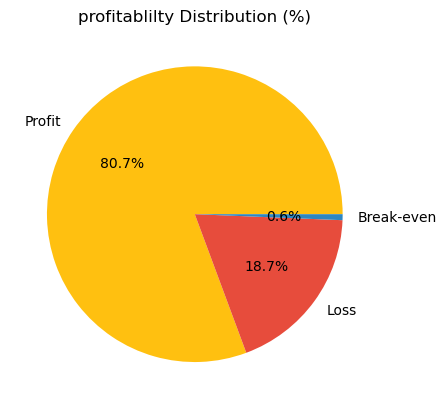

In [22]:
#visualization of Profitability Distribution
accent_color = '#FFC010'
danger_color = '#E74C3C'
secondary_color = '#2E86C1'


Profit_counts=df['Profitablity Flag'].value_counts(normalize=True)*100
Profit_counts.plot(kind='pie',autopct='%1.1f%%', colors=[accent_color, danger_color, secondary_color])
plt.ylabel('')
plt.title('profitablilty Distribution (%)')
plt.show()

In [23]:
#Business KPI's
def format_func(value):
    if value>=1e6:
        return f'{value/1e6:.1f}M $'
    elif value >=1e3:
        return f'{value/1e3:.1f}K $'
    else:
        return f'{value:.0f} $'

delayed_df=df[df['Delay']>0]
metrics={}
metrics['Total Orders']=len(df)
metrics['Late Deliveries']=len(delayed_df)
metrics['90% Delay (days)']=delayed_df['Delay'].quantile(0.90)
metrics['On time Delivery %']= (1-float(metrics['Late Deliveries'])/metrics["Total Orders"])*100
metrics['Late Delivery']=float(metrics['Late Deliveries'])/metrics['Total Orders'] *100
metrics['Total Profit']=format_func(df.loc[df['Delay'] >0, 'Order Profit Per Order'].sum())

print('\n---Business KPIs ---\n')
for k, v in metrics.items():
    if isinstance(v, float):
        print(f"{k}: {v:.2f}")
    else:
        print(f"{k}: {v}")


---Business KPIs ---

Total Orders: 172765
Late Deliveries: 94523
90% Delay (days): 3.00
On time Delivery %: 45.29
Late Delivery: 54.71
Total Profit: 2.1M $


In [25]:
#Profitablity VS Delivery Time Analysis
profit_metrics=(
    df.groupby('Delay')['Order Profit Per Order']
    .agg(
        mean_profit='mean',
        total_profit='sum',
        order_count='count'
    )
    .reset_index()
)

profit_metrics

,Delay,mean_profit,total_profit,order_count
0,-2,23.360134,4.875961e+05,20873
1,-1,21.604769,4.476292e+05,20719
2,0,22.249118,8.154302e+05,36650
3,1,22.333227,1.194895e+06,53503
4,2,21.128491,5.821110e+05,27551
5,3,20.031412,1.356527e+05,6772
6,4,21.368783,1.431067e+05,6697


In [90]:
df.to_csv('DataCoSupplyChainDataset.csv',index=False)

In [26]:
from IPython.display import FileLink, display
display(FileLink('DataCoSupplyChainDataset.csv'))

C:\Users\Harsha vardhan\Downloads\Supply\DataCoSupplyChainDataset.csv

In [93]:
print(df.dtypes.to_string())

Type                                     object
Days for shipping (real)                  int64
Days for shipment (scheduled)             int64
Benefit per order                       float64
Sales per customer                      float64
Delivery Status                          object
Late_delivery_risk                        int64
Category Id                               int64
Category Name                            object
Customer City                            object
Customer Country                         object
Customer Fname                           object
Customer Id                               int64
Customer Segment                         object
Customer State                           object
Customer Street                          object
Department Id                             int64
Department Name                          object
Market                                   object
Order City                               object
Order Country                           

In [94]:
import pandas as pd
print(pd.io.sql.get_schema(df, "staging_orders"))

CREATE TABLE "staging_orders" (
"Type" TEXT,
  "Days for shipping (real)" INTEGER,
  "Days for shipment (scheduled)" INTEGER,
  "Benefit per order" REAL,
  "Sales per customer" REAL,
  "Delivery Status" TEXT,
  "Late_delivery_risk" INTEGER,
  "Category Id" INTEGER,
  "Category Name" TEXT,
  "Customer City" TEXT,
  "Customer Country" TEXT,
  "Customer Fname" TEXT,
  "Customer Id" INTEGER,
  "Customer Segment" TEXT,
  "Customer State" TEXT,
  "Customer Street" TEXT,
  "Department Id" INTEGER,
  "Department Name" TEXT,
  "Market" TEXT,
  "Order City" TEXT,
  "Order Country" TEXT,
  "Order Customer Id" INTEGER,
  "order date (DateOrders)" TIMESTAMP,
  "Order Id" INTEGER,
  "Order Item Cardprod Id" INTEGER,
  "Order Item Discount" REAL,
  "Order Item Discount Rate" REAL,
  "Order Item Id" INTEGER,
  "Order Item Product Price" REAL,
  "Order Item Profit Ratio" REAL,
  "Order Item Quantity" INTEGER,
  "Sales" REAL,
  "Order Item Total" REAL,
  "Order Profit Per Order" REAL,
  "Order Region" T

In [24]:
import pandas as pd
print(pd.io.sql.get_schema(df, "staging_orders"))

CREATE TABLE "staging_orders" (
"Type" TEXT,
  "Days for shipping (real)" INTEGER,
  "Days for shipment (scheduled)" INTEGER,
  "Benefit per order" REAL,
  "Sales per customer" REAL,
  "Delivery Status" TEXT,
  "Late_delivery_risk" INTEGER,
  "Category Id" INTEGER,
  "Category Name" TEXT,
  "Customer City" TEXT,
  "Customer Country" TEXT,
  "Customer Fname" TEXT,
  "Customer Id" INTEGER,
  "Customer Segment" TEXT,
  "Customer State" TEXT,
  "Customer Street" TEXT,
  "Department Id" INTEGER,
  "Department Name" TEXT,
  "Market" TEXT,
  "Order City" TEXT,
  "Order Country" TEXT,
  "Order Customer Id" INTEGER,
  "order date (DateOrders)" TIMESTAMP,
  "Order Id" INTEGER,
  "Order Item Cardprod Id" INTEGER,
  "Order Item Discount" REAL,
  "Order Item Discount Rate" REAL,
  "Order Item Id" INTEGER,
  "Order Item Product Price" REAL,
  "Order Item Profit Ratio" REAL,
  "Order Item Quantity" INTEGER,
  "Sales" REAL,
  "Order Item Total" REAL,
  "Order Profit Per Order" REAL,
  "Order Region" T

In [96]:
import os

print("Current folder:", os.getcwd())

Current folder: c:\Users\Harsha vardhan\Downloads\Supply


In [97]:
import os
print(os.path.abspath("DataCoSupplyChainDataset.csv"))

c:\Users\Harsha vardhan\Downloads\Supply\DataCoSupplyChainDataset.csv


In [98]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 172765 entries, 0 to 180518
Data columns (total 52 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   Type                           172765 non-null  object        
 1   Days for shipping (real)       172765 non-null  int64         
 2   Days for shipment (scheduled)  172765 non-null  int64         
 3   Benefit per order              172765 non-null  float64       
 4   Sales per customer             172765 non-null  float64       
 5   Delivery Status                172765 non-null  object        
 6   Late_delivery_risk             172765 non-null  int64         
 7   Category Id                    172765 non-null  int64         
 8   Category Name                  172765 non-null  object        
 9   Customer City                  172765 non-null  object        
 10  Customer Country               172765 non-null  object        
 11  Custo